<a href="https://colab.research.google.com/github/anniiexp/MAT422/blob/main/3_7_Artificial_Neural_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT422 - Section 3.7: Artificial Neural Networks

In [34]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=5, suppress=True)
rng = np.random.default_rng(422)

## Topics:

*   Mathematical formulation
*   Activation functions

*   Cost function
*   Backpropagation

*   Backpropagation algorithm









# 3.7.1 Mathematical formulation

An artificial neural network is a composition of simple functions. Each layer takes the previous layer's output and applies a linear transformation and then passes the result through a nonlinear nonlinear activation function. For a network with one hidden layer, the forward pass is:

$$
\mathbf{z}^{[1]} = \mathbf{X}\mathbf{W}^{[1]} + \mathbf{b}^{[1]}, \qquad
\mathbf{a}^{[1]} = \tanh(\mathbf{z}^{[1]})
$$

$$
\mathbf{z}^{[2]} = \mathbf{a}^{[1]}\mathbf{W}^{[2]} + \mathbf{b}^{[2]}, \qquad
\hat{\mathbf{y}} = \mathbf{a}^{[2]} = \sigma(\mathbf{z}^{[2]}) = \frac{1}{1 + e^{-\mathbf{z}^{[2]}}}
$$

In these equations, $\mathbf{X}$ holds the input data, with one row per example and
one column per feature. The weight matrices $\mathbf{W}^{[1]}$ and $\mathbf{W}^{[2]}$
and the bias vectors $\mathbf{b}^{[1]}$ and $\mathbf{b}^{[2]}$ are the values the
network learns during training. The $\mathbf{z}$ terms are the raw weighted sums,
and the $\mathbf{a}$ terms are what remains after the activation function is applied.

In [35]:
# XOR dataset: not linearly separable, so a hidden layer is needed
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y = np.array([[0], [1], [1], [0]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# 4 hidden neurons and a larger init scale
n_input, n_hidden, n_output = 2, 4, 1
W1 = rng.normal(scale=0.8, size=(n_input, n_hidden))
b1 = np.zeros((1, n_hidden))
W2 = rng.normal(scale=0.8, size=(n_hidden, n_output))
b2 = np.zeros((1, n_output))

def forward(X):
    z1 = X @ W1 + b1
    a1 = np.tanh(z1)
    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)
    return z1, a1, z2, a2

z1, a1, z2, a2 = forward(X)

# verify the matrix dimensions match the formulation
print("Shapes:")
print("  X:", X.shape, " W1:", W1.shape, " z1/a1:", z1.shape)
print("  W2:", W2.shape, " z2/a2:", a2.shape)

# show the intermediate and final values
print("\nHidden layer activations a1 (one row per input):")
print(a1)
print("\nInitial predicted probabilities vs. true labels:")
for xi, p, t in zip(X, a2, y):
    print(f"  input {xi} -> p = {p[0]:.4f}   (target {int(t[0])})")

x = X[2]  # input [1, 0]
z1_manual = np.array([x[0]*W1[0, j] + x[1]*W1[1, j] + b1[0, j] for j in range(n_hidden)])
a1_manual = np.tanh(z1_manual)
z2_manual = np.sum(a1_manual * W2[:, 0]) + b2[0, 0]
p_manual = 1 / (1 + np.exp(-z2_manual))
print(f"\nManual output for input {x}: {p_manual:.4f}")
print("Matches matrix version:", np.isclose(p_manual, a2[2, 0]))

Shapes:
  X: (4, 2)  W1: (2, 4)  z1/a1: (4, 4)
  W2: (4, 1)  z2/a2: (4, 1)

Hidden layer activations a1 (one row per input):
[[ 0.       0.       0.       0.     ]
 [-0.19009  0.64194 -0.59156 -0.24546]
 [ 0.92286  0.39747  0.48598 -0.88074]
 [ 0.88866  0.82812 -0.14817 -0.92601]]

Initial predicted probabilities vs. true labels:
  input [0. 0.] -> p = 0.5000   (target 0)
  input [0. 1.] -> p = 0.4464   (target 1)
  input [1. 0.] -> p = 0.4587   (target 1)
  input [1. 1.] -> p = 0.4236   (target 0)

Manual output for input [1. 0.]: 0.4587
Matches matrix version: True


The output confirms the formulation: the shapes line up as expected, ending in one predicted probabiltiy per input, and the manual calculation for $[1, 0]$ matches the
matrix result ($0.4587$). The input $[0, 0]$ gives exactly $0.5$ because a zero weighted
sum passes through $\tanh(0) = 0$ and then $\sigma(0) = 0.5$. All predictions fall between about $0.42$ and $0.50$, so the untrained network is essentially guessing and does not yet match the XOR targets. Improving this requires a cost function and a backpropagation to adjust the weights

# 3.7.2 Activation Functions

An activation function is applied to each neuron's weighted sum $z$ to decide the neuron's output. Without it, every later would only perform a linear transformation, and stacking linear layers would still produce a single linear function. Activation functions add nonlinearity, which is what allows a neural network to learn curved decision boundaries and solve problems like XOR.

3 common activation functions are:
$$
\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad
\tanh(z) = \frac{e^{z} - e^{-z}}{e^{z} + e^{-z}}, \qquad
\text{ReLU}(z) = \max(0, z)
$$

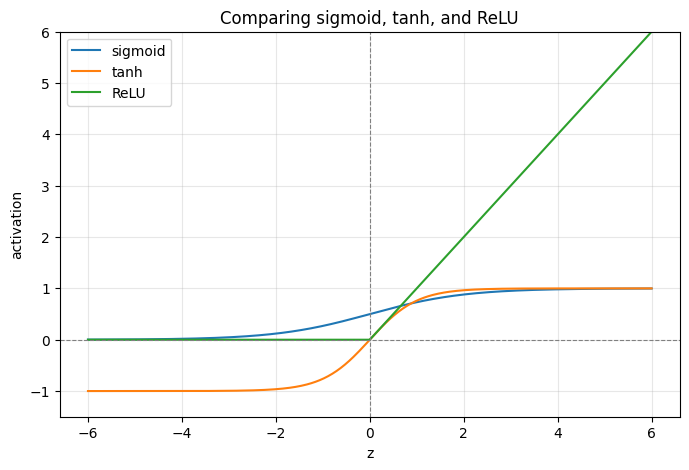

z = -5: sigmoid = 0.0067, tanh = -0.9999, ReLU = 0
z = -2: sigmoid = 0.1192, tanh = -0.9640, ReLU = 0
z = 0: sigmoid = 0.5000, tanh = 0.0000, ReLU = 0
z = 2: sigmoid = 0.8808, tanh = 0.9640, ReLU = 2
z = 5: sigmoid = 0.9933, tanh = 0.9999, ReLU = 5


In [36]:
def relu(z):
  return np.maximum(0, z)

# wider range, added tanh, and reference lines
z = np.linspace(-6, 6, 400)
plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid(z), label="sigmoid")
plt.plot(z, np.tanh(z), label="tanh")
plt.plot(z, relu(z), label="ReLU")
plt.axhline(0, color="gray", linewidth=0.8, linestyle="--")
plt.axvline(0, color="gray", linewidth=0.8, linestyle="--")
plt.ylim(-1.5, 6)
plt.xlabel("z")
plt.ylabel("activation")
plt.title("Comparing sigmoid, tanh, and ReLU")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# print values at a few sample points to compare the functions numerically
sample_z = np.array([-5, -2, 0, 2, 5])
for val in [-5, -2, 0, 2, 5]:
    print(f"z = {val}: sigmoid = {sigmoid(val):.4f}, tanh = {np.tanh(val):.4f}, ReLU = {relu(val)}")

The plot and table show how each function transforms the same input. The sigmoid stays between 0 and 1 and equals exactly $0.5$ at $z = 0$, while $\tanh$ stays between $-1$ and $1$ and equals $0$ at $z = 0$. Both flatten out for large inputs: at $z = 5$, the
sigmoid is already $0.9933$ and $\tanh$ is $0.9999$, so further increases in $z$
barely change the output.

ReLU behaves differently, where it outputs $0$ for every negative input and growing without limit for positive inputs. This is why sigmoid suits probability outputs, while ReLU avoids the flattening that can slow learning in deep networks.

# 3.7.3 Cost Function

A cost function measures how far the network's predictions are from the true labels, turning the overall error into a single number. Training a neural network means adjusting the weights to make this number as small as possible, so the cost function defines what "learning" actually means for the network.

For binary classification, the standard choice is binary cross-entropy:
$$
J = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i \log(\hat{y}_i) + (1 - y_i)\log(1 - \hat{y}_i)\Big]
$$

Target values: [0. 1. 1. 0.]
Initial predicted probabilities: [0.5     0.44636 0.45867 0.42356]
Initial binary cross-entropy = 0.7075

Loss for each example:
  input [0. 0.]: target = 0, p = 0.5000, loss = 0.6931
  input [0. 1.]: target = 1, p = 0.4464, loss = 0.8066
  input [1. 0.]: target = 1, p = 0.4587, loss = 0.7794
  input [1. 1.]: target = 0, p = 0.4236, loss = 0.5509

Comparison:
  good predictions:      0.1054
  always predicting 0.5: 0.6931
  bad predictions:       2.3026


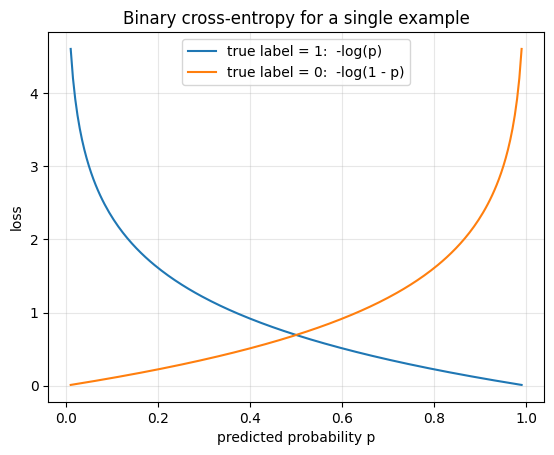

In [37]:
def binary_cross_entropy(y_true, y_prob):
    eps = 1e-9
    loss_pos = y_true * np.log(y_prob + eps)
    loss_neg = (1 - y_true) * np.log(1 - y_prob + eps)
    return -np.mean(loss_pos + loss_neg)

_, _, _, output = forward(X)
print("Target values:", y.ravel())
print("Initial predicted probabilities:", output.ravel())
print(f"Initial binary cross-entropy = {binary_cross_entropy(y, output):.4f}")

# loss for each example
print("\nLoss for each example:")
for xi, t, p in zip(X, y, output):
    loss_i = binary_cross_entropy(t, p)
    print(f"  input {xi}: target = {int(t[0])}, p = {p[0]:.4f}, loss = {loss_i:.4f}")

# compare against made-up predictions
good = np.array([[0.1], [0.9], [0.9], [0.1]])
coin_flip = np.full((4, 1), 0.5)
bad = np.array([[0.9], [0.1], [0.1], [0.9]])
print("\nComparison:")
print(f"  good predictions:      {binary_cross_entropy(y, good):.4f}")
print(f"  always predicting 0.5: {binary_cross_entropy(y, coin_flip):.4f}")
print(f"  bad predictions:       {binary_cross_entropy(y, bad):.4f}")

# plot the loss behavior as the predicted probability changes
p = np.linspace(0.01, 0.99, 200)
plt.plot(p, -np.log(p), label="true label = 1:  -log(p)")
plt.plot(p, -np.log(1 - p), label="true label = 0:  -log(1 - p)")
plt.xlabel("predicted probability p")
plt.ylabel("loss")
plt.title("Binary cross-entropy for a single example")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The untrained network has a cost of $0.7075$, which is slightly worse than simply predicting $0.5$ for ever input, confirming that the random weights have not learned anything yet. The per-example losses show where the network does worst: the two inputs labeled 1 have the highest losses ($0.8066$ and $0.7794$) because their
predictions fall below $0.5$. The comparison shows how the cost rewards accuracy, with correct predictions giving $0.1054$ and confident wrong ones giving $2.3026$.

# 3.7.4 Backpropagation

Backpropagation is the method a neural network uses to figure out how each weight and bias contributed to the error. It starts at the output, where the error is measured by the cost function, and works backward through the network one layer at at time using the chain rule from calculus. The result is a gradient for every parameter: a number that tells us which direction to change it, and by how much, to reduce the cost.



In [38]:
z1, a1, z2, a2 = forward(X)

# backward pass
dz2 = (a2 - y) / len(X)
dW2 = a1.T @ dz2
db2 = dz2.sum(axis=0, keepdims=True)
da1 = dz2 @ W2.T
dz1 = da1 * (1 - np.tanh(z1)**2)
dW1 = X.T @ dz1
db1 = dz1.sum(axis=0, keepdims=True)

# each gradient must have the same shape as its parameter
print("Gradient shapes match parameter shapes:")
print(f"  dW1 {dW1.shape} vs W1 {W1.shape}")
print(f"  db1 {db1.shape} vs b1 {b1.shape}")
print(f"  dW2 {dW2.shape} vs W2 {W2.shape}")
print(f"  db2 {db2.shape} vs b2 {b2.shape}")

print("\nOutput error (a2 - y):", (a2 - y).ravel())

# numerical gradient: nudge one weight and see how the cost changes
h = 1e-5
W1_saved = W1.copy()
W1[0, 0] += h
cost_plus = binary_cross_entropy(y, forward(X)[3])
W1[0, 0] -= 2 * h
cost_minus = binary_cross_entropy(y, forward(X)[3])
W1[:] = W1_saved
numerical = (cost_plus - cost_minus) / (2 * h)
print("\nGradient check for W1[0, 0]:")
print(f"  backpropagation: {dW1[0, 0]:.6f}")
print(f"  numerical:       {numerical:.6f}")
print("  match:", np.isclose(dW1[0, 0], numerical))

lr = 0.5
saved = [W1.copy(), b1.copy(), W2.copy(), b2.copy()]
cost_before = binary_cross_entropy(y, a2)
W1 -= lr * dW1; b1 -= lr * db1; W2 -= lr * dW2; b2 -= lr * db2
cost_after = binary_cross_entropy(y, forward(X)[3])
W1[:], b1[:], W2[:], b2[:] = saved
print(f"\nCost before one update: {cost_before:.4f}")
print(f"Cost after one update:  {cost_after:.4f}")

Gradient shapes match parameter shapes:
  dW1 (2, 4) vs W1 (2, 4)
  db1 (1, 4) vs b1 (1, 4)
  dW2 (4, 1) vs W2 (4, 1)
  db2 (1, 1) vs b2 (1, 1)

Output error (a2 - y): [ 0.5     -0.55364 -0.54133  0.42356]

Gradient check for W1[0, 0]:
  backpropagation: 0.000331
  numerical:       0.000331
  match: True

Cost before one update: 0.7075
Cost after one update:  0.6989


Each gradient has exactly the same shape as its parameter which is required because every weight and bias needs its own update. The output error shows how far each prediction is from its target.

The two inputs labeled 1 have negative errors
($-0.55364$ and $-0.54133$), meaning their predictions are too low, while the inputs
labeled 0 have positive errors, meaning their predictions are too high.

The numerical gradient check gives $0.000331$, which matches the backpropagation result which confirms the chain rule calculations are correct.

Finally, a single gradient descent step lowers the
cost from $0.7075$ to $0.6989$, showing that moving the weights against their gradients
improves the network's predictions.

# 3.7.5 Backpropagation Algorithm

Backpropagation algorithm puts every previous piece together into a training loop.
Each iteration repeats the same four steps:
1. **Forward pass:** compute the predictions $\hat{\mathbf{y}} = \mathbf{a}^{[2]}$ from the
   current weights.
2. **Cost:** measure the error with binary cross-entropy $J$.
3. **Backward pass:** use backpropagation to compute the gradients
   $d\mathbf{W}^{[1]}, d\mathbf{b}^{[1]}, d\mathbf{W}^{[2]}, d\mathbf{b}^{[2]}$.
4. **Update:** move every parameter a small step against its gradient,

$$
\mathbf{W} \leftarrow \mathbf{W} - \alpha \, d\mathbf{W}, \qquad
\mathbf{b} \leftarrow \mathbf{b} - \alpha \, d\mathbf{b}
$$

where $\alpha$ is the learning rate, which controls how large each step is. A single update only improves the network slightly, but repeating the loop many times gradually drives the cost toward zero. If the algorithm works, the network should learn XOR.



step    0: loss = 0.7075
step  500: loss = 0.0049
step 1000: loss = 0.0023
step 1500: loss = 0.0015
step 2000: loss = 0.0011
step 2500: loss = 0.0009

Final loss: 0.0007

Final results:
  input [0. 0.] -> p = 0.0001, prediction = 0, target = 0
  input [0. 1.] -> p = 0.9992, prediction = 1, target = 1
  input [1. 0.] -> p = 0.9990, prediction = 1, target = 1
  input [1. 1.] -> p = 0.0011, prediction = 0, target = 0
Accuracy: 1.0


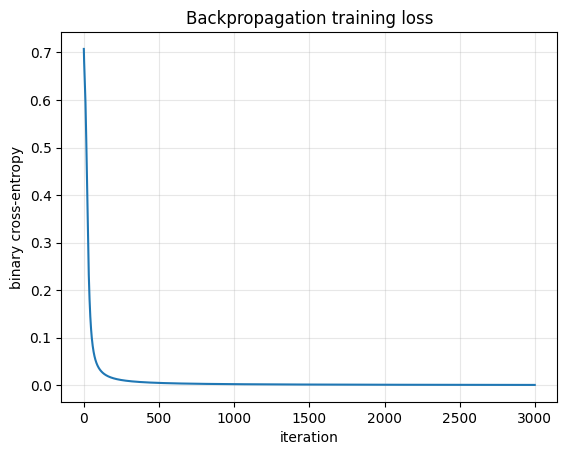

In [39]:
# higher learning rate and more iterations
learning_rate = 1.0
n_steps = 3000
losses = []

for step in range(n_steps):
  # forward pass
  z1 = X @ W1 + b1
  a1 = np.tanh(z1)
  z2 = a1 @ W2 + b2
  a2 = sigmoid(z2)
  losses.append(binary_cross_entropy(y, a2))

  # backward pass
  dz2 = (a2 - y) / len(X)
  dW2 = a1.T @ dz2
  db2 = dz2.sum(axis=0, keepdims=True)
  da1 = dz2 @ W2.T
  dz1 = da1 * (1 - np.tanh(z1)**2)
  dW1 = X.T @ dz1
  db1 = dz1.sum(axis=0, keepdims=True)

  # gradient update
  W2 -= learning_rate * dW2
  b2 -= learning_rate * db2
  W1 -= learning_rate * dW1
  b1 -= learning_rate * db1

  if step % 500 == 0:
    print(f"step {step:>4}: loss = {losses[-1]:.4f}")

# compare
_, _, _, final_output = forward(X)
predictions = (final_output > 0.5).astype(int)
print(f"\nFinal loss: {binary_cross_entropy(y, final_output):.4f}")
print("\nFinal results:")
for xi, p, pred, t in zip(X, final_output, predictions, y):
    print(f"  input {xi} -> p = {p[0]:.4f}, prediction = {pred[0]}, target = {int(t[0])}")
print("Accuracy:", np.mean(predictions == y))

plt.plot(losses)
plt.xlabel("iteration")
plt.ylabel("binary cross-entropy")
plt.title("Backpropagation training loss")
plt.grid(alpha=0.3)
plt.show()

Training starts at a loss of $0.7075$, the same value as the untrained network in the cost functions section, and falls to about $0.0049$ within the first 500 iterations. After that the curve flattens, ending at a final loss of $0.0007$, because the gradients shrink as the predictions approach their targets.

The trained network now outputs
probabilities near 0 for inputs $[0, 0]$ and $[1, 1]$ ($0.0001$ and $0.0011$) and near 1
for $[0, 1]$ and $[1, 0]$ ($0.9992$ and $0.9990$), giving 100% accuracy on XOR. This
shows that repeating the forward pass, backward pass, and update steps lets the network
learn a nonlinear pattern that a single straight line could never separate.

# Reflection

**Mathematical formulation:** Showed that a
neural network is just weighted sums and activation functions stacked together.

**Activation functions:** Comparing sigmoid, tanh, and ReLU showed how each one shapes
its output differently.

**Cost function:** Binary cross-entropy turned the network's error into a single number.
Comparing good, coin-flip, and bad predictions showed how strongly it punishes confident
mistakes.

**Backpropagation:** Using the chain rule, the error is passed backward to find how much
each weight contributed to it. The numerical gradient check confirmed the math was
correct, and one update already lowered the cost.

**Backpropagation algorithm:** Repeating the forward pass, backward pass, and update
steps trained the network to solve XOR with 100% accuracy. Watching the loss drop from
0.7075 to 0.0007 showed how small updates add up to real learning.